<p class="hz-kicker">Week 4 · Live session</p>

# Predicting cancellations

One Altamar booking in three is cancelled, and every cancellation is either an empty room or, if we oversold it, a guest with nowhere to sleep. Today you build a model that gives each booking a probability of cancelling, judge it with the right metric, and set an overbooking policy with money, not habit.

<ul class="hz-lesson-meta"><li>4 hours</li><li>9 ideas</li><li>Runs in your browser</li><li>Case: the right metric</li></ul>

**Setup.** Run this cell first. You don't need to read it: it loads the tools we use today and a small helper that writes dollars nicely.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, roc_auc_score,
                             confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay)

DATA = "https://raw.githubusercontent.com/hizocar/mba-business-analytics-1/main/docs/datasets/"
sns.set_theme(style="whitegrid")
CANCEL, ARRIVE = "#e8590c", "#0c8599"      # colours: cancelled / arrived

def usd(x):
    return f"USD {x:,.0f}"

## <span class="hz-step-n">01</span> Previously at Altamar

Last week the revenue team got a linear model for the nightly rate. Today the **operations team** knocks on the door: **one booking in three is cancelled**. If we keep the room for a guest who cancels, it stays empty. If we resell it (we **overbook**) and the guest does show up, we must *walk* them: pay for a room at another hotel, a taxi and an apology.

So the question is: *which bookings will cancel?* The answer is not a number of dollars but **yes or no**, a **classification** problem. We load the clean bookings from week 2 and count the cancellations, overall and by hotel.

In [2]:
df = pd.read_csv(DATA + "altamar_bookings_clean.csv")
cancelled = df[df["canceled"] == 1]
print(f"{len(df):,} bookings, {len(cancelled):,} cancelled ({df['canceled'].mean():.1%})")
print(f"Room revenue of the cancelled bookings: {usd((cancelled['adr'] * cancelled['nights']).sum())}")
print()
print(df.groupby("hotel")["canceled"].mean().map("{:.1%}".format).to_string())

5,964 bookings, 2,012 cancelled (33.7%)
Room revenue of the cancelled bookings: USD 1,200,647

hotel
Puerto Varas    37.5%
Santiago        25.3%
Viña del Mar    41.1%


**Business takeaway:** about USD 1.2 million of room revenue was booked and then cancelled in two years. Viña del Mar loses four bookings in ten, Santiago one in four. If we knew *which* bookings will cancel, we could resell those rooms and keep most of that money.

## <span class="hz-step-n">02</span> The accuracy trap

How do we judge a model that says "cancels" or "shows up"? The obvious score is **accuracy**: the share of bookings it gets right. It sounds like exactly what we want. But think of the laziest possible model: it says **"nobody cancels"** for every booking. It needs no data at all.

In the simulator, pick a model and slide the cancellation rate. Watch accuracy and the number of cancellations caught.

<div class="hz-widget" data-widget="accuracy-trap">
<p>▶ Interactive simulator: <a href="https://hizocar.github.io/mba-business-analytics-1/sessions/Session_4_Live/">open this session on the course website</a> to use it.</p>
</div>

The same lazy model on the real Altamar bookings: what is its accuracy, and how many cancellations does it catch?

In [3]:
lazy = np.zeros(len(df), dtype="int64")          # predicts 0, "shows up", for everyone
print(f"Accuracy of 'nobody cancels':      {accuracy_score(df['canceled'], lazy):.1%}")
print(f"Cancellations it catches (recall): {recall_score(df['canceled'], lazy):.0%}")

Accuracy of 'nobody cancels':      66.3%
Cancellations it catches (recall): 0%


**Business takeaway:** a model that never predicts a cancellation is right two times in three and resells exactly zero rooms. Accuracy mostly measures how common the bigger group is. From now on every cancellation model must beat **66%**, and we will also look at the cancellations themselves.

<div class="hz-widget" data-widget="quiz">
<script type="application/json">{"q": "A vendor offers Altamar a cancellation model with 67% accuracy. What do you ask first?", "options": ["Nothing: two thirds right is a good grade", "How many of the bookings that really cancelled does it catch?", "Whether it uses more than twenty features"], "answer": 1, "why": "Saying \"nobody cancels\" already scores about 66% on our bookings. Accuracy alone cannot tell a useful model from the lazy one; the share of real cancellations it catches can.", "code": false}</script>
</div>

## <span class="hz-step-n">03</span> From yes/no to a probability

Why not reuse last week's linear regression, with `canceled` (0 or 1) as the target? Its prediction would be a number we could read as a "chance of cancelling". Let's try it with one feature, the **lead time** (days between booking and arrival).

In [4]:
line = LinearRegression().fit(df[["lead_time_days"]], df["canceled"])
for days in [0, 30, 90, 200, 400]:
    guess = line.predict(pd.DataFrame({"lead_time_days": [days]}))[0]
    print(f"Booked {days:3d} days ahead → 'probability' {guess:.2f}")

Booked   0 days ahead → 'probability' 0.23
Booked  30 days ahead → 'probability' 0.30


Booked  90 days ahead → 'probability' 0.42
Booked 200 days ahead → 'probability' 0.66
Booked 400 days ahead → 'probability' 1.08


A booking made 400 days ahead gets a "probability" of 1.08: more than certain. A straight line keeps going forever, so sooner or later it leaves the range 0 to 1.

**Logistic regression** fixes this. It computes a score exactly like a line, then bends it through an **S-curve** (the *sigmoid*) that always stays between 0 and 1: big scores become probabilities near 1, very negative ones near 0. In the simulator, switch between the two models, move the sliders and press *Best fit*.

<div class="hz-widget" data-widget="sigmoid">
<p>▶ Interactive simulator: <a href="https://hizocar.github.io/mba-business-analytics-1/sessions/Session_4_Live/">open this session on the course website</a> to use it.</p>
</div>

**For the curious:** the score is z = b₀ + b₁·x₁ + b₂·x₂ + …, just as in a linear regression, and the probability is p = 1 / (1 + e^(−z)). A score of 0 gives exactly 0.5.

**Watch out:** the simulator stops at 120 days on purpose. Further out, the real risk of cancelling *falls* again, and an S-curve can only go one way. Keep that in mind; section 07 comes back to it.

### Preparing the data

The recipe is last week's, with a new target. **Out of the features:** the booking id (a label), the two dates (we keep only the arrival month) and, of course, `canceled`. **In:** everything we know when the booking is made, including its rate `adr`. Text columns become 0/1 **dummies**; the first category in each list below is the baseline the others are compared with.

In [5]:
y = df["canceled"]
X = df.drop(columns=["booking_id", "booking_date", "arrival_date", "canceled"])
X["arrival_month"] = pd.to_datetime(df["arrival_date"]).dt.month
BASELINE = {"hotel": ["Santiago", "Viña del Mar", "Puerto Varas"], "room_type": ["Standard", "Superior", "Suite"],
            "customer_type": ["Business", "Leisure", "Group"], "deposit": ["No deposit", "Non-refundable"],
            "channel": ["Direct", "Online travel agency", "Corporate", "Travel agent"],
            "country": ["Chile", "Argentina", "Brazil", "United States", "Europe", "Other", "Unknown"]}
for col, order in BASELINE.items():
    X[col] = pd.Categorical(X[col], order)
X = pd.get_dummies(X, columns=list(BASELINE), drop_first=True, dtype="int64")
print(f"{X.shape[1]} features for {len(X):,} bookings")

27 features for 5,964 bookings


Now the train/test split, with one new argument: `stratify=y`. It keeps **the same cancellation rate** in the training and the test bookings, so the test set looks like the real business and no metric is distorted by a lucky cut.

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=42)
print(f"Train: {len(X_train):,} bookings, {y_train.mean():.1%} cancelled")
print(f"Test:  {len(X_test):,} bookings, {y_test.mean():.1%} cancelled")

Train: 4,473 bookings, 33.7% cancelled
Test:  1,491 bookings, 33.7% cancelled


### Training the model

We put a `StandardScaler` in front of `LogisticRegression`, inside a `Pipeline`. **Scaling** puts every feature on the same ruler (lead time in days, the rate in dollars, special requests in units) so the model trains reliably and its coefficients can be compared. The pipeline learns the scaling from the training bookings only.

In [7]:
model = Pipeline([("scale", StandardScaler()),
                  ("logit", LogisticRegression(max_iter=2000))])
model.fit(X_train, y_train)

p_test = model.predict_proba(X_test)[:, 1]          # probability of cancelling, each test booking
print(f"Trained on {len(X_train):,} bookings. Average predicted risk on the test set: {p_test.mean():.1%}")

Trained on 4,473 bookings. Average predicted risk on the test set: 33.9%


`predict_proba` gives each booking two numbers, the probability of showing up and of cancelling; we keep the second. Here are five test bookings, described in words.

In [8]:
test = df.loc[X_test.index].assign(p_cancel=p_test)
for _, b in test.sample(5, random_state=3).iterrows():
    outcome = "cancelled" if b["canceled"] else "arrived"
    print(f"{b['hotel']}, {b['customer_type'].lower()} guest, {b['lead_time_days']} days ahead, "
          f"{b['channel'].lower()}, {b['deposit'].lower()}: {b['p_cancel']:.0%} risk → {outcome}")

Viña del Mar, leisure guest, 90 days ahead, direct, no deposit: 40% risk → cancelled
Santiago, business guest, 4 days ahead, corporate, no deposit: 15% risk → arrived
Santiago, leisure guest, 12 days ahead, direct, no deposit: 18% risk → cancelled
Viña del Mar, leisure guest, 18 days ahead, online travel agency, no deposit: 58% risk → arrived
Viña del Mar, leisure guest, 20 days ahead, travel agent, no deposit: 54% risk → arrived


Read them like a reservations manager. A leisure booking at Viña made 90 days ahead with no deposit: 40%. A business traveller booking Santiago four days ahead through the corporate channel: 15%. But the model is no crystal ball: the Santiago booking at 18% was cancelled, and two Viña bookings above 50% arrived. **A probability is a risk, not a verdict.**

Across all 1,491 test bookings, do the ones that really cancelled get higher probabilities?

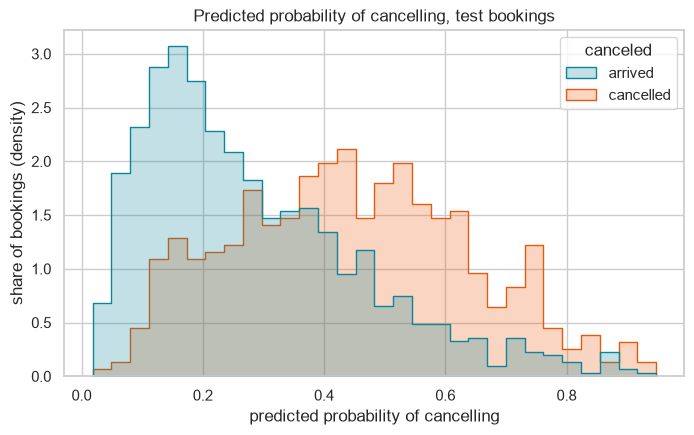

In [9]:
plt.figure(figsize=(8, 4.5))
sns.histplot(x=p_test, hue=y_test.map({0: "arrived", 1: "cancelled"}), hue_order=["arrived", "cancelled"],
             palette={"arrived": ARRIVE, "cancelled": CANCEL}, bins=30, stat="density",
             common_norm=False, element="step")
plt.title("Predicted probability of cancelling, test bookings")
plt.xlabel("predicted probability of cancelling")
plt.ylabel("share of bookings (density)")
plt.show()

Cancelled bookings (orange) tend to sit further right, but the two groups overlap a lot. No single cut-off separates them perfectly, and that is why the next two sections exist.

## <span class="hz-step-n">04</span> The confusion matrix

To act on a probability we need a **threshold**: flag the booking as "likely to cancel", and resell its room, if p ≥ threshold. The default of `model.predict()` is 0.5. Every test booking then lands in one of four cells:

- **Flagged and cancelled:** we resold a room that would have been empty. Revenue saved.
- **Flagged but the guest came:** we have to walk a guest. A *false positive*.
- **Not flagged and cancelled:** the room stays empty. A *false negative*.
- **Not flagged and the guest came:** a normal stay.

In [10]:
pred_05 = (p_test >= 0.5).astype("int64")        # the same as model.predict(X_test)
tn, fp, fn, tp = confusion_matrix(y_test, pred_05).ravel()
print(f"Flagged, cancelled      (room resold):  {tp}")
print(f"Flagged, guest came     (guest walked): {fp}")
print(f"Not flagged, cancelled  (empty room):   {fn}")
print(f"Not flagged, guest came (normal stay):  {tn}")

Flagged, cancelled      (room resold):  201
Flagged, guest came     (guest walked): 126
Not flagged, cancelled  (empty room):   302
Not flagged, guest came (normal stay):  862


The same four numbers as a picture: rows are what really happened, columns what the model predicted.

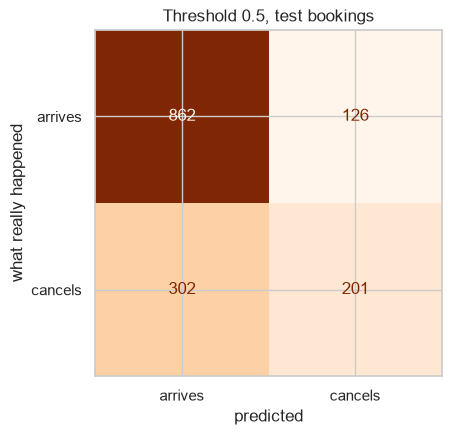

In [11]:
fig, ax = plt.subplots(figsize=(5, 4.5))
ConfusionMatrixDisplay.from_predictions(y_test, pred_05, display_labels=["arrives", "cancels"],
                                        cmap="Oranges", colorbar=False, ax=ax)
ax.set_title("Threshold 0.5, test bookings")
ax.set_xlabel("predicted")
ax.set_ylabel("what really happened")
plt.show()

Two metrics read the matrix from the side of the cancellations:

- **Precision**: of the bookings we flag, how many really cancel? *When we resell a room, how often are we right?* Every miss is a walked guest.
- **Recall**: of the bookings that cancel, how many do we flag? *How many empty rooms do we prevent?*

Both go from 0 to 1. One rises when the other falls, as we will see.

In [12]:
print(f"Accuracy:  {accuracy_score(y_test, pred_05):.1%}   ('nobody cancels' scores {1 - y_test.mean():.1%})")
print(f"Precision: {precision_score(y_test, pred_05):.2f}    of the bookings we flag, the share that cancel")
print(f"Recall:    {recall_score(y_test, pred_05):.2f}    of the cancellations, the share we flag")

Accuracy:  71.3%   ('nobody cancels' scores 66.3%)
Precision: 0.61    of the bookings we flag, the share that cancel
Recall:    0.40    of the cancellations, the share we flag


Read it like the operations manager. At 0.5 we flag 327 bookings and 61% of them really cancel (precision 0.61): about four resales in ten end with a walked guest. And we flag only 201 of the 503 cancellations (recall 0.40), so 302 rooms stay empty. Accuracy, 71.3%, barely beats the lazy 66.3%.

The threshold is a dial, not part of the model. In the simulator, each dot is a real test booking; drag the threshold and watch bookings move between the cells.

<div class="hz-widget" data-widget="threshold">
<p>▶ Interactive simulator: <a href="https://hizocar.github.io/mba-business-analytics-1/sessions/Session_4_Live/">open this session on the course website</a> to use it.</p>
</div>

Now on all test bookings: how many we flag, and what happens to precision and recall, at five thresholds.

In [13]:
rows = []
for t in [0.3, 0.4, 0.5, 0.6, 0.7]:
    flag = p_test >= t
    rows.append({"threshold": t, "bookings flagged": flag.sum(),
                 "precision": precision_score(y_test, flag), "recall": recall_score(y_test, flag)})
pd.DataFrame(rows).round(2)

,threshold,bookings flagged,precision,recall
0,0.3,750,0.50,0.74
1,0.4,524,0.56,0.58
2,0.5,327,0.61,0.40
3,0.6,180,0.62,0.22
4,0.7,97,0.60,0.12


Lower the threshold to 0.3 and we flag 750 bookings: recall jumps to 0.74, but precision falls to 0.50, so half the resales end with a walked guest. Raise it to 0.7 and the list shrinks to 97 bookings that catch only 12% of the cancellations. No row is "right": the best one depends on what an empty room and a walked guest cost.

<div class="hz-widget" data-widget="quiz">
<script type="application/json">{"q": "Operations lowers the threshold from 0.5 to 0.3. What happens?", "options": ["More rooms are resold: recall goes up, precision goes down, more guests are walked", "Both precision and recall go up, because the model gets better", "Nothing changes: the threshold is part of the trained model"], "answer": 0, "why": "A lower bar flags more bookings. More of the real cancellations are among them (recall up), but so are more guests who will arrive (precision down). The model itself is untouched.", "code": false}</script>
</div>

### One number for the whole dial: AUC

Precision and recall depend on the threshold. The **AUC** does not: pick a random booking that cancelled and a random one that arrived; AUC is how often the model gives the cancelled one the higher probability. 0.5 is a coin flip, 1.0 is perfect. The **ROC curve** behind it records every threshold at once. Press *Sweep* in the simulator.

<div class="hz-widget" data-widget="roc">
<p>▶ Interactive simulator: <a href="https://hizocar.github.io/mba-business-analytics-1/sessions/Session_4_Live/">open this session on the course website</a> to use it.</p>
</div>

Our model's ROC curve and AUC on the test bookings.

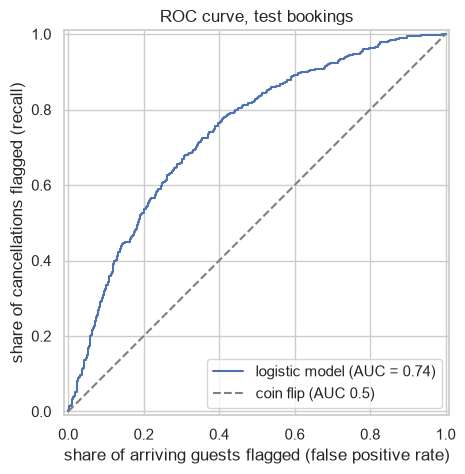

AUC: 0.74


In [14]:
fig, ax = plt.subplots(figsize=(5.5, 5))
RocCurveDisplay.from_predictions(y_test, p_test, name="logistic model", ax=ax)
ax.plot([0, 1], [0, 1], ls="--", color="grey", label="coin flip (AUC 0.5)")
ax.set_title("ROC curve, test bookings")
ax.set_xlabel("share of arriving guests flagged (false positive rate)")
ax.set_ylabel("share of cancellations flagged (recall)")
ax.legend(loc="lower right")
plt.show()
print(f"AUC: {roc_auc_score(y_test, p_test):.2f}")

**Business takeaway:** an AUC of 0.74 means that three times in four the model ranks a booking that will cancel above one that will arrive. The ranking carries real signal; what we do with it depends on where we put the threshold, and that is a money question.

☕ **Break.** Ten minutes. In the second block we turn the probabilities into an overbooking policy, read what drives cancellations, and find where the model goes wrong.

## <span class="hz-step-n">05</span> Choosing the threshold with money

0.5 is a habit, not a decision. The right threshold depends on what each mistake costs. Finance gives us two numbers:

- an **empty room** (a cancellation we did not resell) costs about **USD 400**: an average stay is worth USD 510, and part of it gets resold anyway;
- a **walked guest** (a resold booking whose guest shows up) costs about **USD 300**: another hotel, a taxi, a voucher.

The **overbooking policy**: resell the room of every booking whose probability of cancelling is at least the threshold. The simulator shows its total cost for every threshold, on our real test bookings.

<div class="hz-widget" data-widget="cost-threshold">
<p>▶ Interactive simulator: <a href="https://hizocar.github.io/mba-business-analytics-1/sessions/Session_4_Live/">open this session on the course website</a> to use it.</p>
</div>

The same calculation in code. Change the two costs (✏️) and run the next three cells again.

In [15]:
# ✏️ Change these settings
COST_EMPTY_ROOM = 400   # USD lost when a booking we kept is cancelled and the room stays empty
COST_WALK = 300         # USD to walk a guest whose room we resold: another hotel, taxi, voucher

def policy_cost(threshold, p=p_test, y=y_test):
    resold = p >= threshold
    walked = (resold & (y.values == 0)).sum()       # we resold it and the guest came
    empty = (~resold & (y.values == 1)).sum()       # we kept it and it was cancelled
    return COST_EMPTY_ROOM * empty + COST_WALK * walked

print(f"Do nothing (resell no room): {usd(policy_cost(1.01))}")
print(f"Resell every room:           {usd(policy_cost(0))}")
print(f"Threshold 0.50:              {usd(policy_cost(0.5))}")

Do nothing (resell no room): USD 201,200
Resell every room:           USD 296,400
Threshold 0.50:              USD 158,600


Now every threshold from 0 to 1, and the cheapest one.

In [16]:
thresholds = np.round(np.arange(0, 1.001, 0.01), 2)
costs = pd.DataFrame({"threshold": thresholds,
                      "rooms resold": [(p_test >= t).sum() for t in thresholds],
                      "total cost": [policy_cost(t) for t in thresholds]})
best = costs.loc[costs["total cost"].idxmin()]
print(f"Cheapest threshold {best['threshold']:.2f}: resell {int(best['rooms resold'])} rooms, total {usd(best['total cost'])}")
print(f"  {usd(policy_cost(0.5) - best['total cost'])} less than threshold 0.50")
print(f"  {usd(policy_cost(1.01) - best['total cost'])} less than doing nothing")
print(f"Break-even probability: {COST_WALK} / ({COST_WALK} + {COST_EMPTY_ROOM}) = {COST_WALK / (COST_WALK + COST_EMPTY_ROOM):.2f}")

Cheapest threshold 0.43: resell 451 rooms, total USD 153,100
  USD 5,500 less than threshold 0.50
  USD 48,100 less than doing nothing
Break-even probability: 300 / (300 + 400) = 0.43


The cost curve, with the habit of 0.5 and the cheapest threshold marked.

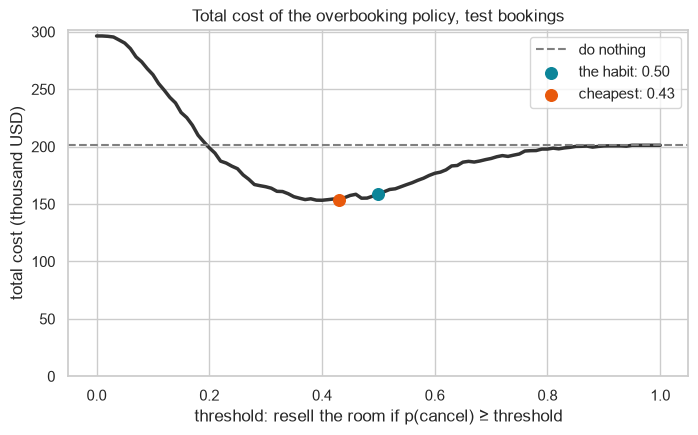

In [17]:
plt.figure(figsize=(8, 4.5))
plt.plot(costs["threshold"], costs["total cost"] / 1000, lw=2.5, color="#333333")
plt.axhline(policy_cost(1.01) / 1000, ls="--", color="grey", label="do nothing")
plt.scatter([0.5], [policy_cost(0.5) / 1000], s=70, zorder=3, color=ARRIVE, label="the habit: 0.50")
plt.scatter([best["threshold"]], [best["total cost"] / 1000], s=70, zorder=3, color=CANCEL,
            label=f"cheapest: {best['threshold']:.2f}")
plt.ylim(0, policy_cost(1.01) / 1000 * 1.5)
plt.title("Total cost of the overbooking policy, test bookings")
plt.xlabel("threshold: resell the room if p(cancel) ≥ threshold")
plt.ylabel("total cost (thousand USD)")
plt.legend()
plt.show()

The cheapest threshold is **0.43**: resell 451 rooms, for USD 48,100 less than doing nothing and USD 5,500 less than the habit of 0.5. Why 0.43? Reselling a booking with probability p costs on average (1 − p) × 300; keeping it costs p × 400. Reselling pays off when p × 400 > (1 − p) × 300, that is, when p > 300 / 700 ≈ 0.43. **The break-even threshold comes from the two costs.**

**Watch out:** we chose the threshold on the test set, the same bookings we use to grade the model. In a real project you choose it on separate **validation** data and keep the test set for the final check.

<div class="hz-widget" data-widget="quiz">
<script type="application/json">{"q": "Guest relations argues that a walked guest also writes a bad review, and puts the cost of a walk at USD 600 instead of 300. The empty room still costs 400. Where does the best threshold move?", "options": ["Down, so that we resell more rooms", "Up, to about 600 / (600 + 400) = 0.6: we only resell rooms we are very sure about", "Nowhere: the model has not changed"], "answer": 1, "why": "Reselling pays off when p × 400 is larger than (1 − p) × 600, so the break-even moves to 0.6. Dearer walks mean fewer, surer resales. Try it with the preset in the simulator.", "code": false}</script>
</div>

## <span class="hz-step-n">06</span> What drives cancellations

The operations manager will ask *why* a booking is risky. Because we scaled the features, the coefficients are comparable: each one says how strongly one standard step of that feature pushes the score up (towards cancelling) or down (towards arriving). Dummies compare against the baseline: a business guest booking direct for a Standard room in Santiago, with no deposit.

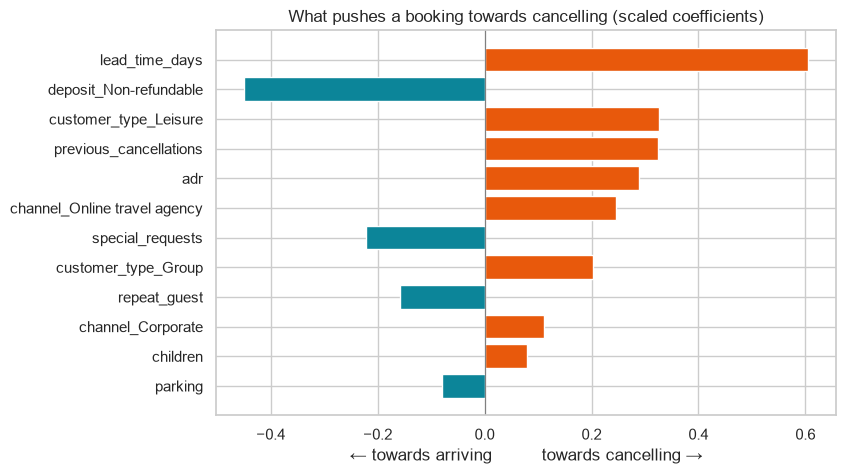

In [18]:
coefs = pd.Series(model.named_steps["logit"].coef_[0], index=X.columns)
top = coefs[coefs.abs().sort_values().index[-12:]]      # the 12 strongest, weakest first
plt.figure(figsize=(8, 5))
plt.barh(top.index, top.values, color=[CANCEL if c > 0 else ARRIVE for c in top])
plt.axvline(0, color="grey", lw=0.8)
plt.title("What pushes a booking towards cancelling (scaled coefficients)")
plt.xlabel("← towards arriving          towards cancelling →")
plt.show()

Reading the chart: **lead time** pushes hardest towards cancelling. So do **leisure** and **group** guests (compared with business travellers), guests who **cancelled before**, **expensive** bookings (`adr`) and the **online travel agency** channel. A **non-refundable deposit** pulls hardest towards arriving, followed by **special requests** and **repeat guests**.

These are **associations, not causes**. The model says that guests with a deposit cancel less; it does not say that a deposit makes anyone keep a booking.

Let's check a few of these stories against the raw cancellation rates.

In [19]:
print(df.groupby("deposit")["canceled"].mean().map("{:.0%}".format).to_string(), "\n")
print(df.groupby(df["previous_cancellations"] > 0)["canceled"].mean()
        .rename({False: "never cancelled before", True: "cancelled before"}).map("{:.0%}".format).to_string(), "\n")
ota_far = (df["channel"] == "Online travel agency") & (df["lead_time_days"] > 45)
print(f"OTA bookings made more than 45 days ahead: {df.loc[ota_far, 'canceled'].mean():.0%} cancel ({ota_far.sum():,} bookings)")
print(f"All other bookings:                        {df.loc[~ota_far, 'canceled'].mean():.0%} cancel")
print(f"Special requests 0 / 1 / 2+:  " + " / ".join(f"{r:.0%}" for r in df.groupby(df["special_requests"].clip(upper=2))["canceled"].mean()))

deposit
No deposit        36%
Non-refundable    19% 

previous_cancellations
never cancelled before    31%
cancelled before          55% 

OTA bookings made more than 45 days ahead: 73% cancel (1,032 bookings)
All other bookings:                        26% cancel
Special requests 0 / 1 / 2+:  34% / 35% / 31%


The raw rates back the deposit and history stories (19% against 36%, 55% against 31%), and OTA bookings made more than 45 days ahead cancel at 73%. Special requests look flat in the raw data, because leisure guests make more requests *and* cancel more; compared with similar bookings, the model finds that a guest who asked for something cancels less. That is what "other things equal" means.

Three actions to test: (1) a **deposit for OTA bookings made far ahead**, the riskiest segment; (2) a **confirmation email** to high-risk bookings, inviting guests to confirm or release the room; (3) treat **repeat guests and guests with requests** as safe when overbooking.

<div class="hz-widget" data-widget="quiz">
<script type="application/json">{"q": "The coefficient of <code>deposit_Non-refundable</code> is clearly negative. Which statement can you defend in front of the general manager?", "options": ["Asking every guest for a non-refundable deposit will cut cancellations in half", "Bookings with a non-refundable deposit cancel less, other things equal; it is worth testing a deposit policy on the riskiest segment", "The deposit is the only thing that matters for cancellations"], "answer": 1, "why": "A coefficient describes an association in past bookings, not a cause: guests who accept a non-refundable deposit may be the ones who were sure anyway. And lead time pushes even harder. The honest move is a test.", "code": false}</script>
</div>

## <span class="hz-step-n">07</span> Where the line fails

Lead time is the strongest driver. But is its effect really "the further ahead, the riskier", as a single coefficient says? We group the test bookings by lead time and compare the share that really cancelled with the model's average probability.

In [20]:
BUCKETS = [0, 15, 30, 45, 60, 75, 90, 105, 120, 150, 180, 240, 500]
test["lead_bucket"] = pd.cut(test["lead_time_days"], BUCKETS, right=False)
by_lead = test.groupby("lead_bucket", observed=True).agg(
    bookings=("canceled", "size"), really_cancelled=("canceled", "mean"), model_says=("p_cancel", "mean"))
by_lead.round(2)

,bookings,really_cancelled,model_says
lead_bucket,,,
"[0, 15)",447,0.15,0.20
"[15, 30)",307,0.23,0.30
"[30, 45)",192,0.34,0.34
"[45, 60)",139,0.48,0.38
"[60, 75)",88,0.65,0.41
"[75, 90)",67,0.70,0.43
"[90, 105)",57,0.74,0.47
"[105, 120)",44,0.59,0.49
"[120, 150)",67,0.43,0.52


The same table as a chart: bars for what really happened, the line for what the model predicts.

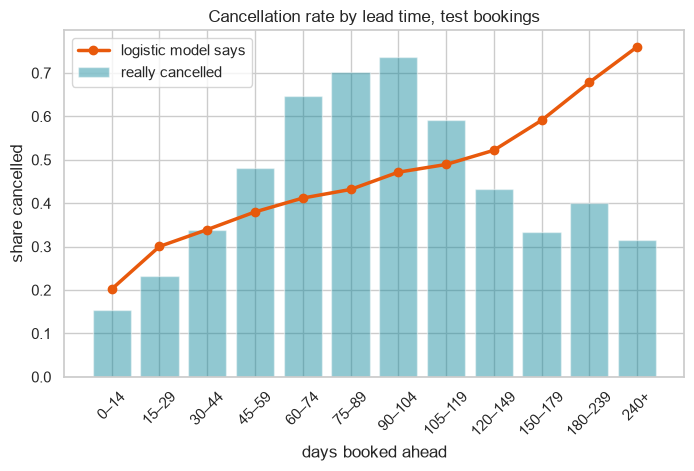

In [21]:
labels = [f"{int(b.left)}–{int(b.right) - 1}" for b in by_lead.index]
labels[-1] = "240+"
plt.figure(figsize=(8, 4.5))
plt.bar(labels, by_lead["really_cancelled"], color=ARRIVE, alpha=0.45, label="really cancelled")
plt.plot(labels, by_lead["model_says"], marker="o", lw=2.5, color=CANCEL, label="logistic model says")
plt.title("Cancellation rate by lead time, test bookings")
plt.xlabel("days booked ahead")
plt.ylabel("share cancelled")
plt.xticks(rotation=45)
plt.legend()
plt.show()

The real rate climbs from 15% for last-minute bookings to **74% for bookings made 90–104 days ahead**, then falls back to about a third for bookings made half a year ahead. The model's line only climbs: it says 41–49% around the peak and 76% for bookings made 240 days ahead or more, which really cancel 32%. Step through the simulator to see why no S-curve can follow the bars.

<div class="hz-widget" data-widget="lead-risk">
<p>▶ Interactive simulator: <a href="https://hizocar.github.io/mba-business-analytics-1/sessions/Session_4_Live/">open this session on the course website</a> to use it.</p>
</div>

**Business takeaway:** the model is wrong in the two places operations cares about most. Around three months out it *underestimates* the risk, so we leave rooms empty; for bookings made half a year ahead it *overestimates* it, so we would resell rooms and walk guests. A straight score, even bent into an S, can only rise. Next week we use models that can bend: curves and **decision trees**.

## <span class="hz-step-n">08</span> What we tell the operations manager

Let's put the policies side by side, on the 1,491 test bookings the model never saw.

In [22]:
def policy(name, resold):
    resold = np.asarray(resold, dtype=bool)
    walked = (resold & (y_test.values == 0)).sum()
    empty = (~resold & (y_test.values == 1)).sum()
    return {"policy": name, "rooms resold": resold.sum(), "guests walked": walked,
            "rooms left empty": empty, "total cost": COST_EMPTY_ROOM * empty + COST_WALK * walked}

t_best = best["threshold"]
plan = pd.DataFrame([policy("Do nothing", p_test > 1),
                     policy("Model, threshold 0.50", p_test >= 0.5),
                     policy(f"Model, threshold {t_best:.2f}", p_test >= t_best)])
plan["saved vs doing nothing"] = plan["total cost"].iloc[0] - plan["total cost"]
plan

,policy,rooms resold,guests walked,rooms left empty,total cost,saved vs doing nothing
0,Do nothing,0,0,503,201200,0
1,"Model, threshold 0.50",327,126,302,158600,42600
2,"Model, threshold 0.43",451,189,241,153100,48100


Doing nothing costs USD 201,200 in empty rooms on these bookings. The model at 0.43 saves **USD 48,100**, about a quarter, or USD 32,000 per 1,000 bookings.

**Top of the pyramid:** *Resell the room of every booking whose predicted risk of cancelling is above 43%; on our test bookings it cuts the cost of cancellations by a quarter.* Then the evidence: who is risky (far ahead, OTA, no deposit), how sure we are (AUC 0.74), and the honest caveats: 189 walked guests is a lot of apologies, and the model misjudges bookings made far ahead.

## <span class="hz-step-n">09</span> Case clinic: the right metric

This week's step of the [applied case](https://hizocar.github.io/mba-business-analytics-1/case/case/) is **the right metric for your decision**. Open the [case toolkit](https://hizocar.github.io/mba-business-analytics-1/case/Case_Toolkit/) with your team.

- **Classification (FinTrust, most own datasets):** compare with the baseline ("nobody defaults"), then read precision, recall and AUC on the test set. Set the **two costs** in section **00 Settings** (approving a client who defaults, rejecting a good one), run section **07 Threshold by cost**, read the **cheapest threshold**, and write where each cost comes from.
- **Regression (TalentCo):** choose between the typical error in dollars (MAE) and R², and say which mistake hurts more.
- Everyone: *"we judge the model by … because the decision is …"*.

**Before next week:** the [lab](https://hizocar.github.io/mba-business-analytics-1/sessions/Session_4_Lab/), An overbooking policy, and its graded quiz. In week 5, [When lines are not enough](https://hizocar.github.io/mba-business-analytics-1/sessions/Session_5_Live/), we go after what both straight lines missed: the cancellation risk that peaks about three months out, and each hotel's own seasons.

<div class="hz-widget" data-widget="quiz">
<script type="application/json">{"q": "FinTrust's risk team says: rejecting a good client loses USD 400 of interest, approving a client who defaults loses USD 4,000. Which metric deserves most attention when choosing the threshold?", "options": ["Accuracy, because it counts every client", "Recall on defaulters: missing a defaulter costs ten times more than rejecting a good client", "Precision on defaulters: every rejected good client is a disaster"], "answer": 1, "why": "When a missed positive is the expensive mistake, you want to catch as many as possible (recall) and accept more false alarms. The costs say where the threshold goes: break-even 400 / (400 + 4,000) ≈ 0.09, a low bar.", "code": false}</script>
</div>